# Module 3 — Phase 2: Synthetic Tampering Dataset Generation
**AI Passport Screening System — India → Bangladesh Border Checkpoint**

> **Label Basis Note:**  
> Genuine samples = original source passport images used as reference for this  
> **synthetic research dataset only**. Real-world passport authenticity is UNKNOWN.  
> ELA scores are NOT used to assign labels.
>
> All tampered samples are synthetic research data produced by documented  
> transformations. They are NOT real forged documents.

## Cell 1 — Imports and Project Path

In [1]:
import sys, os, json

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print('Project root:', PROJECT_ROOT)

Project root: C:\Users\priya\Desktop\prototype


## Cell 2 — Dataset Output Configuration (edit paths here)

In [2]:
# ── EDIT THESE ────────────────────────────────────────────────────────────────

# Source passport images (existing project images)
SOURCE_DIR   = os.path.join(PROJECT_ROOT, 'passport')

# Output dataset root (must match Phase 3 notebook DATASET_ROOT)
DATASET_ROOT = os.path.join(PROJECT_ROOT, 'data', 'tampering_dataset')

# Global RNG seed for reproducibility
SEED = 42

# Portrait region override — set to None to use the default synthetic layout.
# For real passport scans the box may need adjustment.
# Format: (left, top, right, bottom) in pixels.
PHOTO_REGION = None   # e.g. (30, 115, 200, 295)

print('Source dir  :', SOURCE_DIR)
print('Dataset root:', DATASET_ROOT)
print('Seed        :', SEED)

Source dir  : C:\Users\priya\Desktop\prototype\passport
Dataset root: C:\Users\priya\Desktop\prototype\data\tampering_dataset
Seed        : 42


## Cell 3 — Source Passport Image Discovery

In [3]:
from app.tampering.dataset_builder import discover_source_images

source_images = discover_source_images(SOURCE_DIR)
print(f'Found {len(source_images)} source image(s):')
for p in source_images:
    size_kb = os.path.getsize(p) // 1024
    print(f'  {p.name:25s}  {size_kb:5d} KB')

Found 13 source image(s):
  passport1.jpg                108 KB
  passport10.jpg                51 KB
  passport11.jpg                87 KB
  passport12.jpg                59 KB
  passport13.jpg                81 KB
  passport2.jpg                168 KB
  passport3.jpg                132 KB
  passport4.jpg                 78 KB
  passport5.jpg                 76 KB
  passport6.jpg                 77 KB
  passport7.jpg                111 KB
  passport8.jpg                 75 KB
  passport9.jpg                 95 KB


## Cell 4 — Source Image and Label Readiness Check
> Confirms images can be opened. Flags label-basis caveats.

In [4]:
from PIL import Image

ok, failed = [], []
for p in source_images:
    try:
        img = Image.open(p)
        img.verify()
        ok.append((p.name, Image.open(p).size))
    except Exception as exc:
        failed.append((p.name, str(exc)))

print(f'\n✅ Openable images: {len(ok)}')
for name, sz in ok:
    print(f'  {name:25s}  {sz[0]}×{sz[1]} px')

if failed:
    print(f'\n❌ Failed to open: {len(failed)}')
    for name, err in failed:
        print(f'  {name}: {err}')

print()
print('⚠️  LABEL BASIS NOTE:')
print('  These source images are used as "genuine" references for the synthetic')
print('  research dataset ONLY. Their real-world authenticity is UNKNOWN.')
print('  Confirm authenticity manually before using as confirmed genuine labels.')

if failed:
    raise RuntimeError(f'{len(failed)} image(s) could not be opened — fix before generating.')


✅ Openable images: 13
  passport1.jpg              768×540 px
  passport10.jpg             768×540 px
  passport11.jpg             768×540 px
  passport12.jpg             953×651 px
  passport13.jpg             1012×517 px
  passport2.jpg              768×540 px
  passport3.jpg              768×540 px
  passport4.jpg              768×540 px
  passport5.jpg              768×540 px
  passport6.jpg              768×540 px
  passport7.jpg              768×540 px
  passport8.jpg              768×540 px
  passport9.jpg              768×540 px

⚠️  LABEL BASIS NOTE:
  These source images are used as "genuine" references for the synthetic
  research dataset ONLY. Their real-world authenticity is UNKNOWN.
  Confirm authenticity manually before using as confirmed genuine labels.


## Cell 5 — Tampering Generation Configuration

In [5]:
# Review which operations will be applied (informational — no code to edit)
from app.tampering.synthetic_ops import TEXT_REGIONS, _DEFAULT_PHOTO_REGION

print('Tampering operations that will be applied per source image:')
print('  A. photo_replacement    — portrait region swapped with donor image crop')
print('  B. text_region_blot     — date_of_birth field overwritten (crude PIL font)')
print('  C. region_copypaste     — MRZ strip self-copied to mid-body region')
print('  D. local_colour_shift   — date_of_expiry region brightness+hue shift')
print()
print('Default photo region:', PHOTO_REGION or _DEFAULT_PHOTO_REGION)
print('Available text regions:', list(TEXT_REGIONS.keys()))
print()
print('Per source image: 1 genuine + up to 4 tampered variants')
print(f'Expected total (if all succeed): {len(source_images)} genuine + {len(source_images)*4} tampered')

Tampering operations that will be applied per source image:
  A. photo_replacement    — portrait region swapped with donor image crop
  B. text_region_blot     — date_of_birth field overwritten (crude PIL font)
  C. region_copypaste     — MRZ strip self-copied to mid-body region
  D. local_colour_shift   — date_of_expiry region brightness+hue shift

Default photo region: (30, 115, 200, 295)
Available text regions: ['date_of_birth', 'date_of_expiry', 'passport_number', 'surname', 'given_names', 'date_of_issue']

Per source image: 1 genuine + up to 4 tampered variants
Expected total (if all succeed): 13 genuine + 52 tampered


## Cell 6 — Generate Synthetic Tampering Variants
⏳ This writes images to disk. May take a moment for 13 source images.

In [6]:
from app.tampering.dataset_builder import build_dataset

gen_result = build_dataset(
    source_dir   = SOURCE_DIR,
    dataset_root = DATASET_ROOT,
    seed         = SEED,
    photo_region = PHOTO_REGION,
)

print('Success:', gen_result['success'])

records = gen_result['records']
succeeded = [r for r in records if r.get('success')]
failed    = [r for r in records if not r.get('success')]

print(f'Total records  : {len(records)}')
print(f'Succeeded      : {len(succeeded)}')
print(f'Failed         : {len(failed)}')

if failed:
    print('\n⚠️  Failed records (will NOT appear in manifest):')
    for r in failed:
        print(f'  {r["sample_id"]:50s}  ERROR: {r["error"]}')

if gen_result['errors']:
    print('\n❌ Builder errors:')
    for e in gen_result['errors']:
        print(' ', e)
    raise RuntimeError('Dataset build failed — see errors above.')

print('\nManifests written to:')
print('  Full :', gen_result['full_manifest_path'])
print('  Phase3:', gen_result['p3_manifest_path'])
print('Summary:', gen_result['summary_path'])

Success: True
Total records  : 65
Succeeded      : 65
Failed         : 0

Manifests written to:
  Full : C:\Users\priya\Desktop\prototype\data\tampering_dataset\manifests\dataset_manifest.csv
  Phase3: C:\Users\priya\Desktop\prototype\data\tampering_dataset\manifest.csv
Summary: C:\Users\priya\Desktop\prototype\data\tampering_dataset\reports\generation_summary.json


## Cell 7 — Display Original vs Synthetic Samples

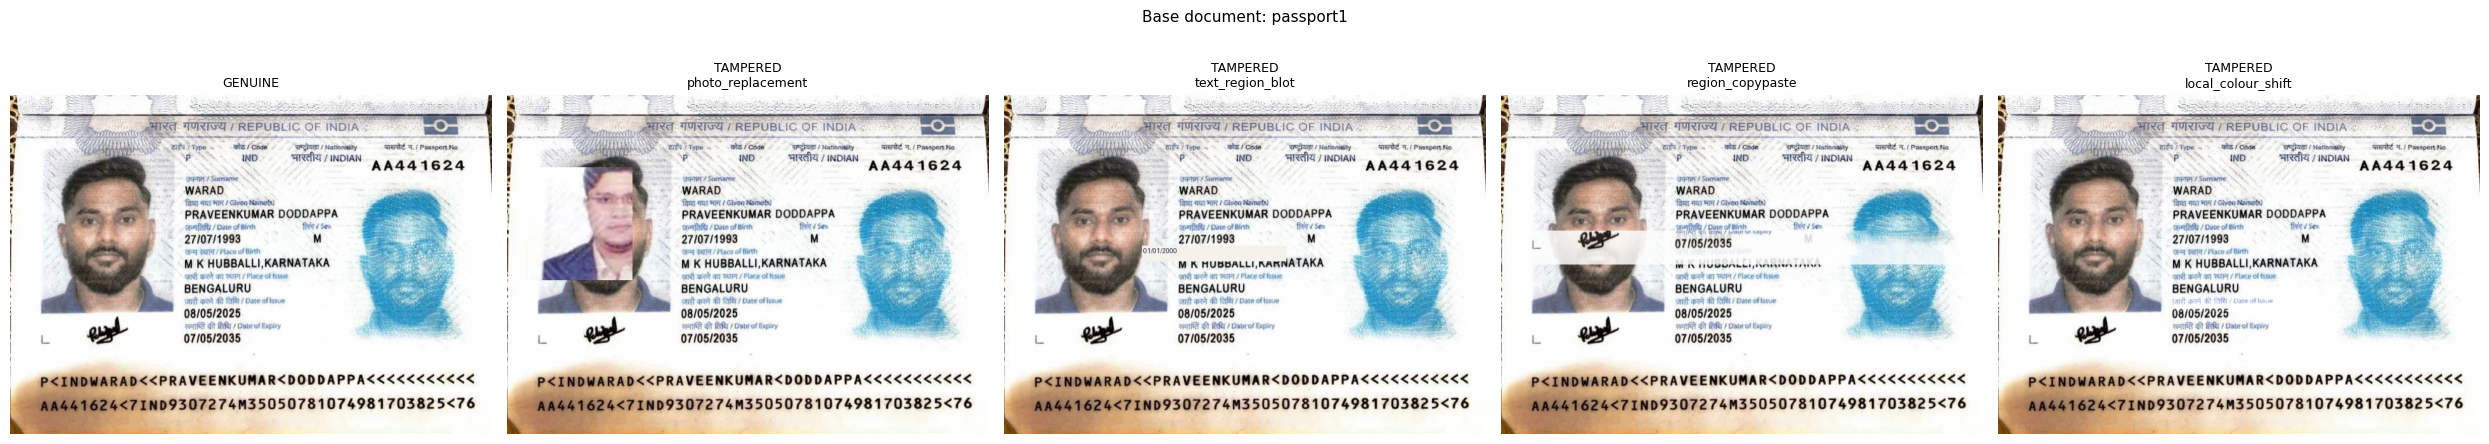

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Show first source image and its tampered variants
source_images_list = [r for r in succeeded if r['label'] == 0]
if not source_images_list:
    print('No genuine samples to display.')
else:
    first_base_id = source_images_list[0]['base_document_id']
    group = [r for r in succeeded if r['base_document_id'] == first_base_id]

    n = len(group)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    for ax, rec in zip(axes, group):
        img_path = os.path.join(DATASET_ROOT, rec['image_path'])
        try:
            img = Image.open(img_path)
            ax.imshow(img)
        except Exception as exc:
            ax.text(0.5, 0.5, f'Error:\n{exc}', ha='center', va='center')
        label = 'GENUINE' if rec['label'] == 0 else f'TAMPERED\n{rec["tampering_type"]}'
        ax.set_title(label, fontsize=9)
        ax.axis('off')

    plt.suptitle(f'Base document: {first_base_id}', fontsize=11)
    plt.tight_layout()
    plt.show()

## Cell 8 — Dataset Manifest Inspection

In [8]:
import csv
import os

manifest_path = os.path.join(DATASET_ROOT, 'manifest.csv')
print('Phase-3-compatible manifest.csv:', manifest_path)

with open(manifest_path, newline='', encoding='utf-8') as f:
    rows = list(csv.DictReader(f))

print(f'Total rows: {len(rows)}')
print('Columns   :', list(rows[0].keys()) if rows else '(empty)')
print()
print('First 5 rows:')
for r in rows[:5]:
    print(' ', r)

# Also show full manifest columns
full_manifest = os.path.join(DATASET_ROOT, 'manifests', 'dataset_manifest.csv')
with open(full_manifest, newline='', encoding='utf-8') as f:
    full_rows = list(csv.DictReader(f))
print(f'\nFull manifest columns: {list(full_rows[0].keys()) if full_rows else "(empty)"}')

Phase-3-compatible manifest.csv: C:\Users\priya\Desktop\prototype\data\tampering_dataset\manifest.csv
Total rows: 65
Columns   : ['image_path', 'label', 'base_document_id']

First 5 rows:
  {'image_path': 'images\\genuine\\passport1\\passport1_genuine_original.jpg', 'label': '0', 'base_document_id': 'passport1'}
  {'image_path': 'images\\tampered\\passport1\\passport1_tampered_photo_repl_42.jpg', 'label': '1', 'base_document_id': 'passport1'}
  {'image_path': 'images\\tampered\\passport1\\passport1_tampered_text_dob_42.jpg', 'label': '1', 'base_document_id': 'passport1'}
  {'image_path': 'images\\tampered\\passport1\\passport1_tampered_copypaste_42.jpg', 'label': '1', 'base_document_id': 'passport1'}
  {'image_path': 'images\\tampered\\passport1\\passport1_tampered_colourshift_42.jpg', 'label': '1', 'base_document_id': 'passport1'}

Full manifest columns: ['image_path', 'label', 'base_document_id', 'sample_id', 'class_name', 'source_image', 'is_synthetic', 'tampering_type', 'affected_r

## Cell 9 — Dataset Validation

In [9]:
from app.tampering.dataset_builder import validate_dataset

val = validate_dataset(DATASET_ROOT)

print('Valid           :', val['valid'])
print('Total rows      :', val['total'])
print('Genuine         :', val['genuine_count'])
print('Tampered        :', val['tampered_count'])
print('Missing files   :', val['missing_files']  or 'none')
print('Invalid labels  :', val['invalid_labels'] or 'none')
print('Duplicates      :', val['duplicates']     or 'none')
print('Errors          :', val['errors']         or 'none')

if not val['valid']:
    print('\n⚠️  Dataset validation FAILED — check issues above before training.')
else:
    print('\n✅ Dataset validation passed.')

Valid           : True
Total rows      : 65
Genuine         : 13
Tampered        : 52
Missing files   : none
Invalid labels  : none
Duplicates      : none
Errors          : none

✅ Dataset validation passed.


## Cell 10 — Class-Count Summary

Class distribution:
  GENUINE   :   13  █████████████
  TAMPERED  :   52  ████████████████████████████████████████████████████
  Total     : 65
  Balance   : 20.0% genuine / 80.0% tampered


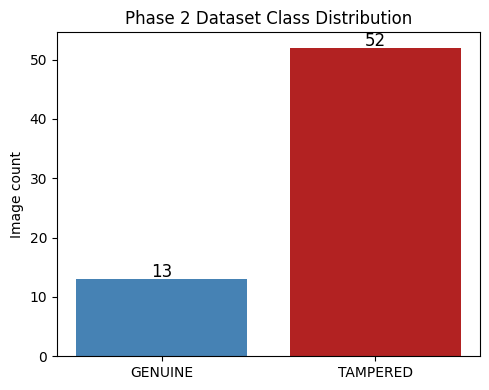

In [10]:
import matplotlib.pyplot as plt

labels_list = ['GENUINE', 'TAMPERED']
counts      = [val['genuine_count'], val['tampered_count']]

print('Class distribution:')
for lbl, cnt in zip(labels_list, counts):
    bar = '█' * cnt
    print(f'  {lbl:10s}: {cnt:4d}  {bar}')

total = sum(counts)
print(f'  Total     : {total}')
if total > 0:
    print(f'  Balance   : {counts[0]/total*100:.1f}% genuine / {counts[1]/total*100:.1f}% tampered')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(labels_list, counts, color=['steelblue', 'firebrick'])
ax.set_title('Phase 2 Dataset Class Distribution')
ax.set_ylabel('Image count')
for i, v in enumerate(counts):
    ax.text(i, v + 0.3, str(v), ha='center', fontsize=12)
plt.tight_layout()
plt.show()

## Cell 11 — Optional: ELA Comparison Using Phase 1 Module
> ELA scores are for DIAGNOSTIC INSPECTION only — NOT used to assign labels.

Genuine  — mean_ela: 0.6060667634010315  max_ela: 10.0
Tampered — mean_ela: 0.5934494137763977  max_ela: 10.0

⚠️  ELA values are DIAGNOSTIC only — they were NOT used to assign labels.


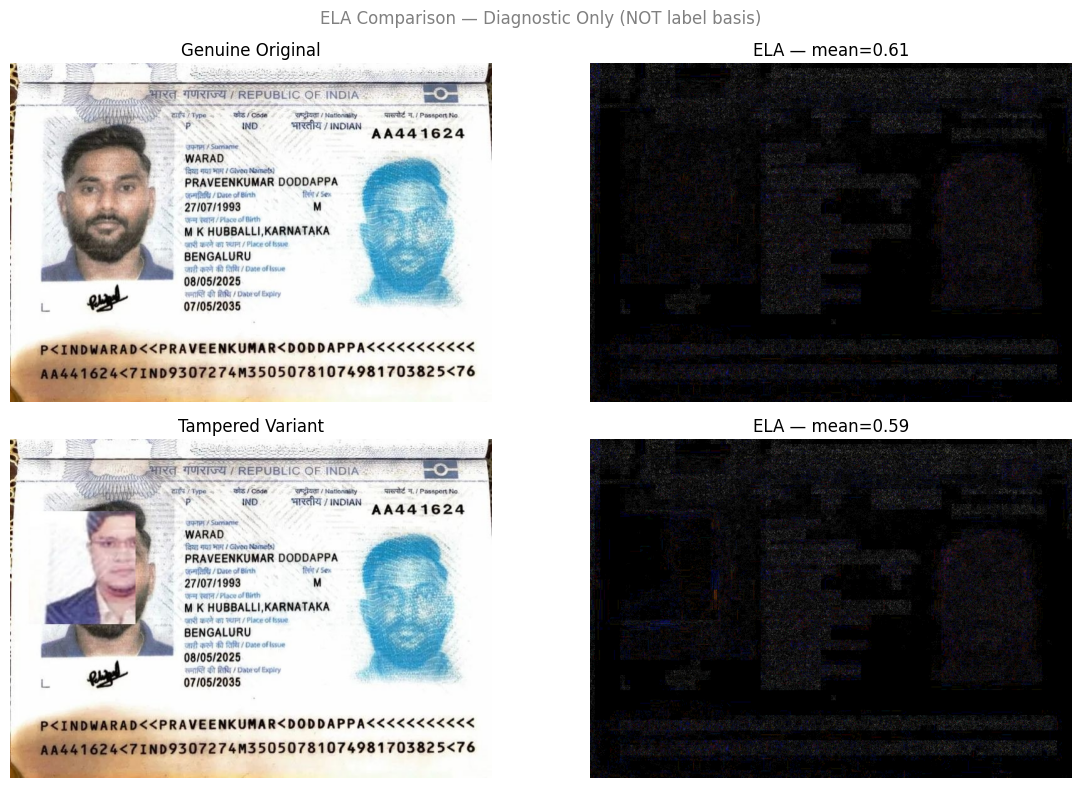

In [11]:
from app.tampering.ela_analyzer import run_ela
import os
import matplotlib.pyplot as plt
from PIL import Image

# Pick the first genuine and first tampered from the same base document
genuine_recs  = [r for r in succeeded if r['label'] == 0]
tampered_recs = [r for r in succeeded if r['label'] == 1]

if not genuine_recs or not tampered_recs:
    print('Not enough samples for ELA comparison.')
else:
    g_path = os.path.join(DATASET_ROOT, genuine_recs[0]['image_path'])
    t_path = os.path.join(DATASET_ROOT, tampered_recs[0]['image_path'])

    g_ela = run_ela(g_path, save_path=None)
    t_ela = run_ela(t_path, save_path=None)

    print('Genuine  — mean_ela:', g_ela.get('mean_ela'), ' max_ela:', g_ela.get('max_ela'))
    print('Tampered — mean_ela:', t_ela.get('mean_ela'), ' max_ela:', t_ela.get('max_ela'))
    print()
    print('⚠️  ELA values are DIAGNOSTIC only — they were NOT used to assign labels.')

    if g_ela['success'] and t_ela['success']:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        axes[0,0].imshow(Image.open(g_path));           axes[0,0].set_title('Genuine Original');  axes[0,0].axis('off')
        axes[0,1].imshow(g_ela['ela_image']);            axes[0,1].set_title(f'ELA — mean={g_ela["mean_ela"]:.2f}'); axes[0,1].axis('off')
        axes[1,0].imshow(Image.open(t_path));           axes[1,0].set_title('Tampered Variant');  axes[1,0].axis('off')
        axes[1,1].imshow(t_ela['ela_image']);            axes[1,1].set_title(f'ELA — mean={t_ela["mean_ela"]:.2f}'); axes[1,1].axis('off')
        plt.suptitle('ELA Comparison — Diagnostic Only (NOT label basis)', color='gray')
        plt.tight_layout()
        plt.show()

## Cell 12 — Save Dataset Generation Report

In [12]:
import json, os

summary_path = gen_result['summary_path']
print('Generation summary saved to:', summary_path)

with open(summary_path, encoding='utf-8') as f:
    summary = json.load(f)

print(json.dumps(summary, indent=2))

Generation summary saved to: C:\Users\priya\Desktop\prototype\data\tampering_dataset\reports\generation_summary.json
{
  "phase": "Phase 2 \u2014 Synthetic Tampering Dataset Generation",
  "source_dir": "C:\\Users\\priya\\Desktop\\prototype\\passport",
  "dataset_root": "C:\\Users\\priya\\Desktop\\prototype\\data\\tampering_dataset",
  "total_records": 65,
  "successful": 65,
  "failed": 0,
  "genuine_count": 13,
  "tampered_count": 52,
  "tampering_types": [
    "photo_replacement",
    "region_copypaste",
    "text_region_blot",
    "local_colour_shift"
  ],
  "failed_records": [],
  "label_note": "Genuine labels indicate original source images used as reference for this synthetic research dataset. Real-world passport authenticity is UNKNOWN and requires manual review. ELA scores were NOT used to assign labels.",
  "synthetic_note": "All tampered samples are synthetic research data generated by documented image transformations. They are NOT real forged documents."
}


## Cell 13 — Phase 3 Compatibility Check

In [13]:
from app.tampering.dataset_loader import check_dataset_readiness, load_dataset

print('=== Phase 3 dataset_loader compatibility check ===')
readiness = check_dataset_readiness(DATASET_ROOT)

print('Ready           :', readiness['ready'])
print('Has manifest    :', readiness['has_manifest'])
print('Genuine count   :', readiness['genuine_count'])
print('Tampered count  :', readiness['tampered_count'])

if readiness['issues']:
    for issue in readiness['issues']:
        print('⚠️  Issue:', issue)

if readiness['ready']:
    ds = load_dataset(DATASET_ROOT)
    if ds['success']:
        print('\n✅ Phase 3 load_dataset() succeeded.')
        print('   Source     :', ds['source'])
        print('   Classes    :', ds['class_counts'])
        print('   Splits     :', ds['split_counts'])
    else:
        print('\n❌ load_dataset() failed:')
        for e in ds['errors']:
            print('  ', e)
else:
    print('\n⚠️  Dataset not yet ready for Phase 3 — see issues above.')

=== Phase 3 dataset_loader compatibility check ===
Ready           : True
Has manifest    : True
Genuine count   : 13
Tampered count  : 52

✅ Phase 3 load_dataset() succeeded.
   Source     : manifest
   Classes    : {'GENUINE': 13, 'TAMPERED': 52}
   Splits     : {'train': 45, 'val': 10, 'test': 10}
